<a href="https://colab.research.google.com/github/nicolastibata/MINE_4210_ADL_202620/blob/main/assingments/assingment_3/MINE_4210_ADL_202620_T3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

![Logo ADL](https://github.com/nicolastibata/MINE_4210_ADL_202620/blob/main/docs/logo.png?raw=true)


# **Taller 3: Clasificación de textos con modelos encoder**

### **Contexto y Objetivos**

En 2015, la Organización de las Naciones Unidas (ONU) adoptó la Agenda 2030, que establece 17 Objetivos de Desarrollo Sostenible (ODS) y 169 metas orientadas a enfrentar desafíos sociales, económicos y ambientales. En este contexto, organizaciones como el Fondo de Población de las Naciones Unidas (UNFPA) trabajan con instituciones públicas para identificar problemas y evaluar políticas mediante mecanismos de participación ciudadana. Uno de los principales desafíos es analizar la información textual recopilada en estos procesos, ya que requiere tiempo, recursos y conocimiento experto para relacionarla con los ODS. Automatizar este análisis facilitaría la identificación de las necesidades de la población y apoyaría la toma de decisiones y la formulación de políticas públicas alineadas con la Agenda 2030.

En el Laboratorio 6 este problema se resolvió con una red LSTM y una capa de embeddings aprendida desde cero. En este taller utilizarán BETO, un modelo BERT preentrenado en español, para analizar cómo cambia el desempeño cuando el modelo parte de representaciones contextuales preentrenadas. También compararán dos formas de aprovechar el modelo: como extractor de características fijo y mediante ajuste fino (fine-tuning).

<br>

**Conjunto de datos:** Se utilizará el archivo TextosODS.xlsx (los del [lab6](https://github.com/nicolastibata/MINE_4210_ADL_202620/blob/main/labs/Laboratorio_6/TextosODS.xlsx)), que contiene 9.656 fragmentos de textos (columna textos) etiquetados con uno de los ODS 1 a 16 (columna ODS). Para el entrenamiento, conviertan las etiquetas al rango 0–15. Este conjunto permite estudiar la clasificación temática por ODS, aunque sus textos académicos no representan necesariamente los textos obtenidos en procesos de participación ciudadana.

Dividan los datos en entrenamiento (70 %), validación (15 %) y prueba (15 %) de forma estratificada, con random_state=42. Pueden separar primero el 15 % para prueba y después reservar 15/85 de los datos restantes para validación. Utilicen las mismas particiones en todos los experimentos.

<br>

**Actividades**

**1. Exploración previa:** Antes de entrenar los modelos.

- Calculen la distribución de la longitud de los textos en tokens de BETO, incluyendo los tokens especiales y antes del truncamiento, y el porcentaje que supera 256 tokens.
- Revisen la distribución de clases.
- Construyan un diagrama de cajas de la longitud de los textos (en tokens) por ODS.

<br>

**2. Modelo para construir:** El objetivo es construir y comparar los siguientes enfoques.

A diferencia del modelo utilizado en el Laboratorio de BERT, que está en inglés y se carga desde TF Hub, BETO está disponible en Hugging Face (dccuchile/bert-base-spanish-wwm-cased). Para los modelos 2 y 3 utilizarán la librería transformers con PyTorch. El siguiente ejemplo muestra únicamente cómo cargar el tokenizador y el modelo base; deberán investigar cómo extraer representaciones y cómo realizar el ajuste fino. Indiquen en el notebook las fuentes que consultaron.

```python
from transformers import AutoTokenizer, AutoModel
MODELO = "dccuchile/bert-base-spanish-wwm-cased"
# Cargar el tokenizador y el modelo
tokenizer = AutoTokenizer.from_pretrained(MODELO)
model = AutoModel.from_pretrained(MODELO)
# Ejemplo de tokenización
texto = "La educación de calidad es fundamental para el desarrollo sostenible."
entradas = tokenizer(texto, return_tensors="pt")
print(tokenizer.convert_ids_to_tokens(entradas["input_ids"][0]))
```

- Modelo 1 (línea base): la LSTM del Laboratorio 6. Pueden reutilizar su código, pero deben reentrenarla con las particiones de este taller y reportar las mismas métricas que para los demás modelos.

- Modelo 2 (BETO congelado):

  - Modelo: dccuchile/bert-base-spanish-wwm-cased, sin modificar sus pesos.

  - Representación de cada texto: promedio de los vectores de la última capa, ponderado por la máscara de atención (mean pooling), lo que produce un vector de 768 dimensiones.

  - Cabeza de clasificación: Dense(256, activation='relu') + Dropout(0.3) + Dense(16, activation='softmax').

  - Entrenamiento: máximo 20 épocas, con EarlyStopping sobre val_loss y patience=4.

  - **Sugerencia:** calculen las representaciones una sola vez y guárdenlas, de modo que el entrenamiento de la cabeza no requiera volver a pasar los textos por BETO.

- Modelo 3 (BETO con ajuste fino):

  - AutoModelForSequenceClassification con el mismo modelo base y 16 clases.

  - Congelen los embeddings y los primeros 10 bloques encoder. Entrenen únicamente los últimos 2 bloques encoder y la cabeza de clasificación.

La siguiente tabla resume las diferencias entre los tres enfoques:

| Modelo | Representación del texto | Pesos del encoder | Cabeza de clasificación |
|-|-|-|-|
| Modelo 1 | Embeddings aprendidos desde cero + LSTM | Se entrenan desde cero | La del Laboratorio 6 |
| Modelo 2 | BETO (mean pooling) | Congelados | MLP |
| Modelo 3 | BETO | Solo los últimos 2 bloques encoder (fine-tuning) | Capa lineal de AutoModelForSequenceClassification |

**Configuración:**
- max_length = 256 para los modelos 2 y 3.
- Modelo 3 (fine tuning parcial). Tasa de aprendizaje 2e-5, tamaño de lote 16, máximo 3 épocas y weight decay 0,01. Pueden utilizar precisión mixta (FP16) para reducir el consumo de memoria y acelerar el entrenamiento si la GPU lo permite. Conserven el checkpoint con mayor F1 macro en validación y utilícenlo para evaluar el conjunto de prueba.
- Utilicen GPU (por ejemplo, Colab con T4).

<br>

**3. Resultados**. Para cada modelo reporten:

- Accuracy y F1 macro en el conjunto de prueba.
- F1-score por clase.
- Matriz de confusión.
- Número de parámetros entrenables y tiempo aproximado de entrenamiento. Para el Modelo 2, reporten por separado el tiempo de extracción de embeddings y el de entrenamiento de la cabeza de clasificación.
- Curvas de loss de entrenamiento y validación.
Presenten los resultados en una tabla que permita comparar los tres enfoques.

<br>

**4. Análisis**. A partir de los resultados, respondan:

1. ¿Cómo se ordenan los tres modelos según su desempeño? ¿Qué diferencias en la forma de representar el texto explican ese orden? ¿En qué se parece la comparación entre la LSTM y BETO congelado a la que hicieron en el Taller 2 entre la CNN desde cero y transfer learning?
2. ¿Qué diferencias encuentran entre el desempeño de BETO congelado y BETO con ajuste fino? ¿Cómo influye la adaptación de las representaciones a la tarea de clasificación?
3. Identifiquen los pares de ODS que más se confunden. Revisen 5 errores del mejor modelo y clasifíquenlos en: error del modelo, ambigüedad temática o etiqueta potencialmente dudosa (sin asumir que está incorrecta). ¿Qué indican estos casos sobre formular el problema con una sola etiqueta por texto?
4. Según el diagrama de cajas, ¿hay ODS cuyos textos sean claramente más largos o cortos que los demás? ¿Qué implicaría esto si un modelo aprendiera a usar la longitud como señal para clasificar?
5. Si una organización necesitara clasificar miles de documentos con recursos de cómputo limitados, ¿qué enfoque recomendarían y por qué? Distingan el costo de entrenamiento del costo de inferencia.

**Bono (hasta 15 % adicional).** Repitan el ajuste fino parcial del Modelo 3 con Bertin (https://huggingface.co/bertin-project/bertin-roberta-base-spanish, congelando los embeddings y los primeros 10 bloques encoder. Reporten las mismas métricas y respondan: ¿mejora el desempeño frente a BETO? ¿Qué diferencias entre los dos modelos (corpus de preentrenamiento, tokenizador, procedimiento de preentrenamiento) podrían explicar el resultado?


### **Entregable**

Notebook (.ipynb) con todas las celdas ejecutadas y con todas las indicaciones anteriormente estipuladas en la sección de laboratorios en **Bloque Neón**.



### **Rúbrica**

| Criterio | Peso | Qué se evalúa |
|-|-|-|
| Exploración previa | 10 % | Distribución de longitudes en tokens, distribución de clases y análisis de longitud por ODS. |
| Modelo 1. LSTM | 10 % | Reentrenamiento correcto con las particiones del taller. |
| Modelo 2. BETO congelado | 20 % | Extracción correcta de representaciones (mean pooling con máscara de atención) y entrenamiento de la cabeza MLP. |
| Modelo 3. BETO con ajuste fino | 20 % | Carga y configuración correcta de BETO para clasificación, entrenamiento completo y selección del modelo con el conjunto de validación. |
| Evaluación y presentación de resultados | 10 % | Métricas, matrices de confusión y costo computacional, organizados para facilitar la comparación. |
| Análisis e interpretación | 30 % | Comparación justificada entre enfoques, análisis de errores y discusión sobre atajos y sobre la formulación del problema. |
| Bono. Bertin | +15 % | Entrenamiento con la misma configuración, reporte de métricas y comparación justificada con BETO. |

---
# **Solución — Taller 3**

En este notebook se desarrollan los puntos **1 (exploración previa)**, **2 (modelos)**
y **3 (resultados)**. Todos los experimentos comparten las mismas particiones
(70 % / 15 % / 15 %, estratificadas, `random_state=42`).

> **Entorno de ejecución.** Este notebook se ejecutó de forma **local** sobre una GPU
> **NVIDIA RTX 2070** con PyTorch (`cu124`) + Transformers, y TensorFlow/Keras para la
> LSTM. También es reproducible en Colab (T4): basta seleccionar un entorno con GPU y
> ejecutar las celdas en orden.

**Fuentes consultadas** (además del material de la asignatura y el Laboratorio 6):
- Hugging Face Transformers — *Auto Classes* (`AutoTokenizer`, `AutoModel`,
  `AutoModelForSequenceClassification`): https://huggingface.co/docs/transformers/model_doc/auto
- Model card de BETO: https://huggingface.co/dccuchile/bert-base-spanish-wwm-cased
- Mean pooling ponderado por la máscara de atención (patrón estándar de *sentence
  embeddings*): https://www.sbert.net/examples/applications/computing-embeddings/README.html
- `BertModel` (`last_hidden_state`, `attention_mask`):
  https://huggingface.co/docs/transformers/model_doc/bert


## 0. Configuración e importaciones

In [1]:
# En Colab, descomentar para instalar dependencias que no vienen por defecto:
# !pip -q install "transformers>=4.44" "accelerate>=0.26" openpyxl

import os, time, math, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from transformers import AutoTokenizer, AutoModel, AutoModelForSequenceClassification

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

MODELO = "dccuchile/bert-base-spanish-wwm-cased"
MAX_LENGTH = 256
NUM_CLASSES = 16
sns.set_theme(style="whitegrid")

# Diccionario donde iremos acumulando los resultados de cada modelo (punto 3).
resultados = {}


Dispositivo: cuda
GPU: NVIDIA GeForce RTX 2070


## Carga de datos y particiones comunes

Se cargan los 9 656 fragmentos de `TextosODS.xlsx`. Las etiquetas ODS (1–16) se
convierten al rango **0–15**. Los datos se dividen de forma **estratificada** en
entrenamiento (70 %), validación (15 %) y prueba (15 %) con `random_state=42`:
primero se separa el 15 % de prueba y luego se reserva 15/85 del resto para validación.
**Estas mismas particiones se usan en los tres modelos.**

In [2]:
ods_names = {
    1: "Fin de la pobreza", 2: "Hambre cero", 3: "Salud y Bienestar",
    4: "Educación de Calidad", 5: "Igualdad de Género",
    6: "Agua limpia y Saneamiento", 7: "Energía asequible y no contaminante",
    8: "Trabajo decente y crecimiento económico",
    9: "Industria, Innovación e Infraestructura",
    10: "Reducción de las desigualdades", 11: "Ciudades y comunidades sostenibles",
    12: "Producción y consumo responsable", 13: "Acción por el clima",
    14: "Vida submarina", 15: "Vida de ecosistemas terrestres",
    16: "Paz, Justicia e Instituciones Sólidas",
}

_local = "TextosODS.xlsx"
if os.path.exists(_local):
    df = pd.read_excel(_local)
else:
    url = ("https://github.com/nicolastibata/MINE_4210_ADL_202620/"
           "raw/main/labs/Laboratorio_6/TextosODS.xlsx")
    df = pd.read_excel(url)

df = df.dropna(subset=["textos", "ODS"]).reset_index(drop=True)
df["textos"] = df["textos"].astype(str)
df["ODS"] = df["ODS"].astype(int)
df["label"] = df["ODS"] - 1   # 1..16 -> 0..15

print("Total de ejemplos:", len(df))
print("Rango de ODS:", df["ODS"].min(), "a", df["ODS"].max())
print("Rango de label:", df["label"].min(), "a", df["label"].max())
df.head()


Total de ejemplos: 9656
Rango de ODS: 1 a 16
Rango de label: 0 a 15


,textos,ODS,label
0,"""Aprendizaje"" y ""educación"" se consideran sinó...",4,3
1,No dejar clara la naturaleza de estos riesgos ...,6,5
2,"Como resultado, un mayor y mejorado acceso al ...",13,12
3,Con el Congreso firmemente en control de la ju...,16,15
4,"Luego, dos secciones finales analizan las impl...",5,4


In [3]:
texts = df["textos"].tolist()
labels = df["label"].values

# 1) 15% de prueba
train_val_texts, test_texts, train_val_labels, test_labels = train_test_split(
    texts, labels, test_size=0.15, random_state=42, stratify=labels)

# 2) 15/85 del resto para validación (= 15% del total)
val_frac = 0.15 / 0.85
train_texts, val_texts, train_labels, val_labels = train_test_split(
    train_val_texts, train_val_labels, test_size=val_frac,
    random_state=42, stratify=train_val_labels)

print(f"Entrenamiento: {len(train_texts):>5}  ({len(train_texts)/len(df)*100:.1f}%)")
print(f"Validación:    {len(val_texts):>5}  ({len(val_texts)/len(df)*100:.1f}%)")
print(f"Prueba:        {len(test_texts):>5}  ({len(test_texts)/len(df)*100:.1f}%)")

CLASS_NAMES = [f"ODS {i+1}" for i in range(NUM_CLASSES)]  # 0..15 -> ODS 1..16


Entrenamiento:  6758  (70.0%)
Validación:     1449  (15.0%)
Prueba:         1449  (15.0%)


# **1. Exploración previa**

Antes de entrenar los modelos analizamos: (a) la distribución de la longitud de los
textos en **tokens de BETO** (incluyendo tokens especiales `[CLS]`/`[SEP]` y **antes**
de truncar), junto con el porcentaje que supera 256 tokens; (b) la distribución de
clases; y (c) un diagrama de cajas de la longitud por ODS.

In [4]:
# Tokenizador de BETO (lo reutilizaremos en los modelos 2 y 3)
tokenizer = AutoTokenizer.from_pretrained(MODELO)

# Ejemplo de tokenización (como en el enunciado)
texto_demo = "La educación de calidad es fundamental para el desarrollo sostenible."
entradas_demo = tokenizer(texto_demo, return_tensors="pt")
print(tokenizer.convert_ids_to_tokens(entradas_demo["input_ids"][0]))


['[CLS]', 'La', 'educación', 'de', 'calidad', 'es', 'fundamental', 'para', 'el', 'desarrollo', 'sostenible', '.', '[SEP]']


In [5]:
# Longitud en tokens de BETO para TODOS los textos, con tokens especiales y SIN truncar.
# add_special_tokens=True incluye [CLS] y [SEP]; truncation=False -> longitud real.
token_lengths = []
for i in range(0, len(df), 512):
    batch = df["textos"].iloc[i:i+512].tolist()
    enc = tokenizer(batch, add_special_tokens=True, truncation=False,
                    padding=False)
    token_lengths.extend(len(ids) for ids in enc["input_ids"])

df["n_tokens"] = token_lengths
tok = np.array(token_lengths)

print("Estadísticas de longitud en tokens (con tokens especiales, sin truncar):")
print(pd.Series(tok).describe(percentiles=[.5, .75, .90, .95, .99]).round(2))

pct_over_256 = (tok > MAX_LENGTH).mean() * 100
print(f"\nPorcentaje de textos que superan {MAX_LENGTH} tokens: {pct_over_256:.2f}%")
print(f"Textos que superan {MAX_LENGTH}: {(tok > MAX_LENGTH).sum()} de {len(tok)}")


Estadísticas de longitud en tokens (con tokens especiales, sin truncar):
count    9656.00
mean      136.89
std        45.53
min        27.00
50%       129.50
75%       165.25
90%       201.00
95%       221.00
99%       259.00
max       363.00
dtype: float64

Porcentaje de textos que superan 256 tokens: 1.13%
Textos que superan 256: 109 de 9656


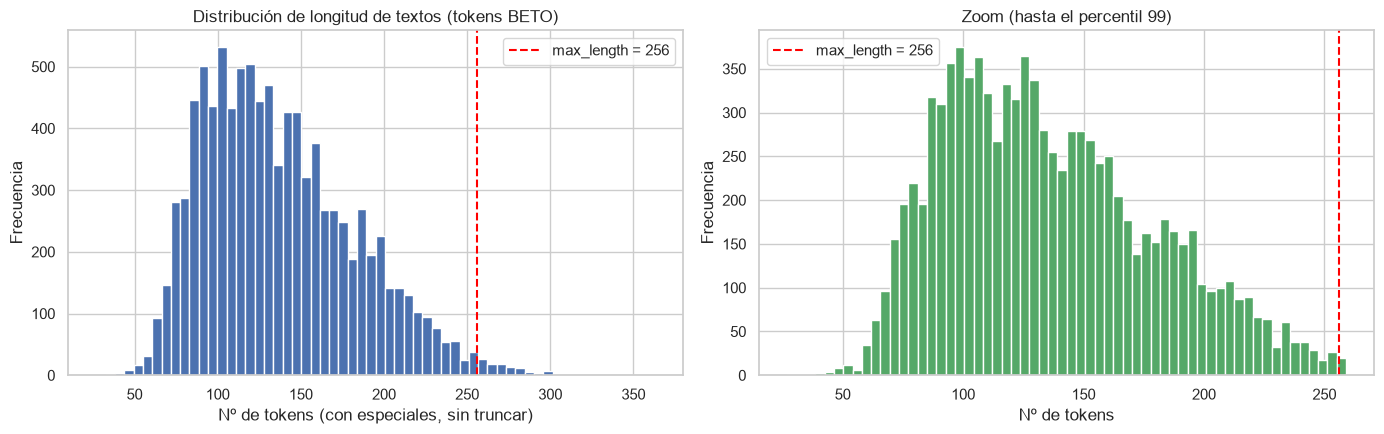

In [6]:
# Histograma de la distribución de longitudes en tokens
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))

ax[0].hist(tok, bins=60, color="#4C72B0", edgecolor="white")
ax[0].axvline(MAX_LENGTH, color="red", linestyle="--",
              label=f"max_length = {MAX_LENGTH}")
ax[0].set_title("Distribución de longitud de textos (tokens BETO)")
ax[0].set_xlabel("Nº de tokens (con especiales, sin truncar)")
ax[0].set_ylabel("Frecuencia")
ax[0].legend()

# Zoom hasta el percentil 99 para apreciar el grueso de la distribución
p99 = np.percentile(tok, 99)
ax[1].hist(tok[tok <= p99], bins=60, color="#55A868", edgecolor="white")
ax[1].axvline(MAX_LENGTH, color="red", linestyle="--",
              label=f"max_length = {MAX_LENGTH}")
ax[1].set_title("Zoom (hasta el percentil 99)")
ax[1].set_xlabel("Nº de tokens")
ax[1].set_ylabel("Frecuencia")
ax[1].legend()
plt.tight_layout(); plt.show()


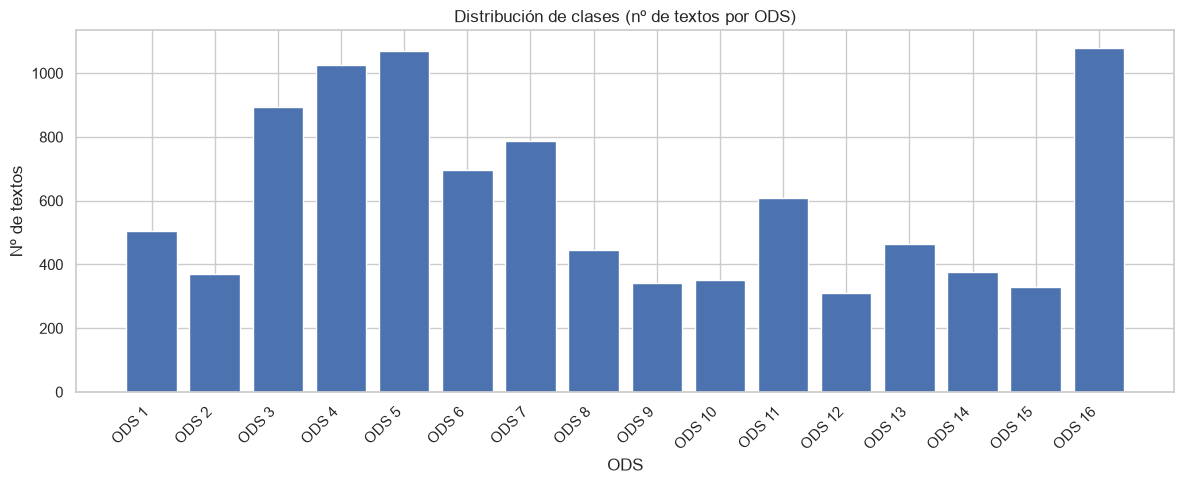

Conteo por ODS:
 ODS                                  nombre    n  porcentaje
   1                       Fin de la pobreza  505        5.23
   2                             Hambre cero  369        3.82
   3                       Salud y Bienestar  894        9.26
   4                    Educación de Calidad 1025       10.62
   5                      Igualdad de Género 1070       11.08
   6               Agua limpia y Saneamiento  695        7.20
   7     Energía asequible y no contaminante  787        8.15
   8 Trabajo decente y crecimiento económico  446        4.62
   9 Industria, Innovación e Infraestructura  343        3.55
  10          Reducción de las desigualdades  352        3.65
  11      Ciudades y comunidades sostenibles  607        6.29
  12        Producción y consumo responsable  312        3.23
  13                     Acción por el clima  464        4.81
  14                          Vida submarina  377        3.90
  15          Vida de ecosistemas terrestres  330     

In [7]:
# Distribución de clases (ODS)
counts = df["ODS"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar([f"ODS {i}" for i in counts.index], counts.values, color="#4C72B0")
ax.set_title("Distribución de clases (nº de textos por ODS)")
ax.set_xlabel("ODS"); ax.set_ylabel("Nº de textos")
plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.show()

print("Conteo por ODS:")
dist = pd.DataFrame({
    "ODS": counts.index,
    "nombre": [ods_names[i] for i in counts.index],
    "n": counts.values,
    "porcentaje": (counts.values / counts.values.sum() * 100).round(2),
})
print(dist.to_string(index=False))
print(f"\nRatio desbalance (max/min): {counts.max()/counts.min():.2f}")


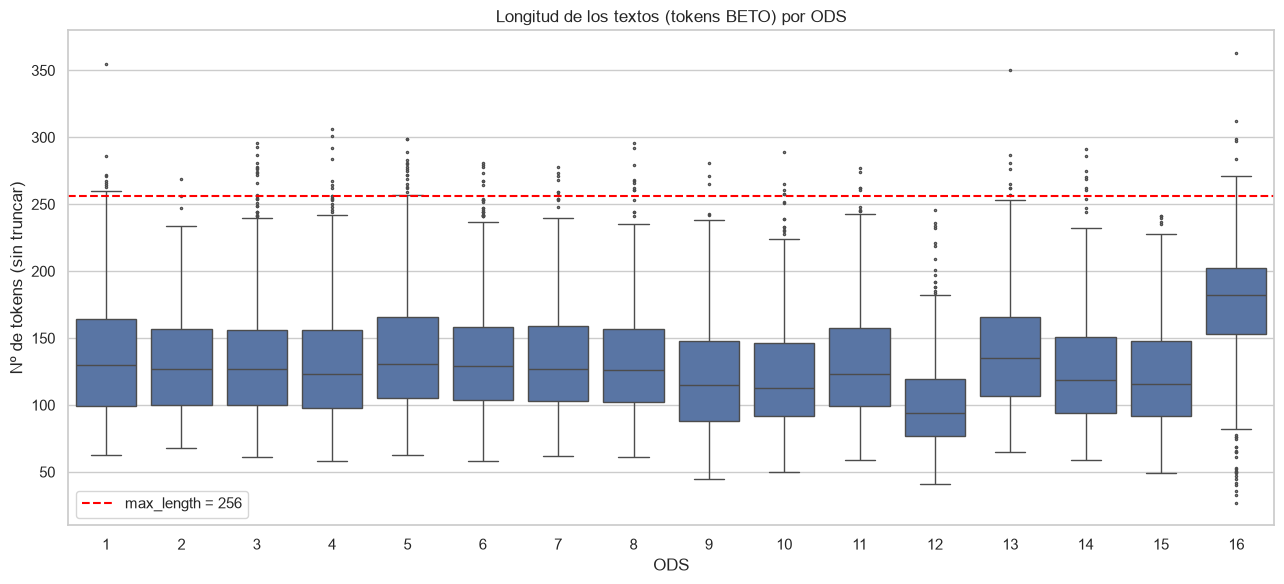

Mediana de longitud (tokens) por ODS, ordenada:
ODS
12     94.0
10    113.0
9     115.0
15    116.0
14    119.0
4     123.0
11    123.0
8     126.0
2     127.0
3     127.0
7     127.0
6     129.0
1     130.0
5     131.0
13    135.0
16    182.0


In [8]:
# Diagrama de cajas de la longitud (en tokens) por ODS
fig, ax = plt.subplots(figsize=(13, 6))
order = sorted(df["ODS"].unique())
sns.boxplot(data=df, x="ODS", y="n_tokens", order=order,
            showfliers=True, fliersize=1.5, ax=ax)
ax.axhline(MAX_LENGTH, color="red", linestyle="--", label=f"max_length = {MAX_LENGTH}")
ax.set_title("Longitud de los textos (tokens BETO) por ODS")
ax.set_xlabel("ODS"); ax.set_ylabel("Nº de tokens (sin truncar)")
ax.legend()
plt.tight_layout(); plt.show()

# Mediana de longitud por ODS (apoyo para el análisis del punto 4)
med = df.groupby("ODS")["n_tokens"].median().sort_values()
print("Mediana de longitud (tokens) por ODS, ordenada:")
print(med.to_string())


# **2. Modelos**

Se construyen y comparan tres enfoques:

| Modelo | Representación del texto | Pesos del encoder | Cabeza de clasificación |
|-|-|-|-|
| **1** | Embeddings aprendidos desde cero + LSTM | Se entrenan desde cero | La del Laboratorio 6 |
| **2** | BETO (mean pooling) | Congelados | MLP (256 → 16) |
| **3** | BETO | Solo los últimos 2 bloques encoder (fine-tuning) | Capa lineal de `AutoModelForSequenceClassification` |

Primero definimos utilidades de evaluación comunes a los tres modelos.

In [9]:
def evaluar_modelo(nombre, y_true, y_pred, history=None,
                   trainable_params=None, train_time=None, extra=None):
    """Calcula métricas, dibuja matriz de confusión y curvas de loss,
    y guarda todo en el diccionario global `resultados`."""
    acc = accuracy_score(y_true, y_pred)
    f1_macro = f1_score(y_true, y_pred, average="macro")
    f1_per_class = f1_score(y_true, y_pred, average=None,
                            labels=list(range(NUM_CLASSES)))

    print(f"===== {nombre} =====")
    print(f"Accuracy (test):  {acc:.4f}")
    print(f"F1 macro (test):  {f1_macro:.4f}")
    if trainable_params is not None:
        print(f"Parámetros entrenables: {trainable_params:,}")
    if train_time is not None:
        print(f"Tiempo de entrenamiento: {train_time:.1f} s")
    if extra:
        for k, v in extra.items():
            print(f"{k}: {v}")
    print("\nReporte de clasificación por clase:")
    print(classification_report(y_true, y_pred,
                                labels=list(range(NUM_CLASSES)),
                                target_names=CLASS_NAMES, digits=3,
                                zero_division=0))

    # Matriz de confusión
    cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))
    plt.figure(figsize=(9, 7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                cbar_kws={"shrink": .8})
    plt.xlabel("Predicción"); plt.ylabel("ODS real")
    plt.title(f"Matriz de confusión — {nombre}")
    plt.tight_layout(); plt.show()

    # Curvas de loss
    if history is not None:
        tr = history.get("loss"); va = history.get("val_loss")
        if tr is not None and va is not None:
            plt.figure(figsize=(7, 4))
            plt.plot(range(1, len(tr)+1), tr, marker="o", label="train loss")
            plt.plot(range(1, len(va)+1), va, marker="o", label="val loss")
            plt.xlabel("Época"); plt.ylabel("Loss")
            plt.title(f"Curvas de loss — {nombre}")
            plt.legend(); plt.tight_layout(); plt.show()

    resultados[nombre] = {
        "accuracy": acc, "f1_macro": f1_macro,
        "f1_per_class": f1_per_class,
        "trainable_params": trainable_params,
        "train_time_s": train_time,
        "history": history, "confusion_matrix": cm,
        "y_true": np.asarray(y_true), "y_pred": np.asarray(y_pred),
        "extra": extra or {},
    }
    return resultados[nombre]


## Modelo 1 — LSTM (línea base, Laboratorio 6)

Se reutiliza la arquitectura del Laboratorio 6 (capa de *Embedding* entrenable +
LSTM + capa densa *softmax*), pero **reentrenada con las particiones de este taller**.
Se usan los pesos de clase balanceados y *EarlyStopping* sobre `val_loss`.
Las métricas finales se reportan sobre el conjunto de **prueba**.

In [10]:
import tensorflow as tf
# TensorFlow se ejecuta en CPU: la LSTM es ligera y así evitamos que el
# compilador XLA de TF busque el toolkit CUDA del sistema (libdevice).
# BETO (PyTorch) sí usa la GPU, pues trae su propio runtime CUDA.
try:
    tf.config.set_visible_devices([], 'GPU')
except Exception as _e:
    print('Aviso al ocultar GPU a TF:', _e)
print('Dispositivos GPU visibles para TF:', tf.config.get_visible_devices('GPU'))
from tensorflow.keras.preprocessing.text import Tokenizer as KerasTokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Hiperparámetros de la LSTM (como en el Laboratorio 6)
MAX_WORDS = 10000
MAX_SEQUENCE_LENGTH = 50
EMBEDDING_DIM = 64

# Tokenizador Keras ajustado SOLO con el conjunto de entrenamiento
keras_tok = KerasTokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
keras_tok.fit_on_texts(train_texts)

def a_secuencias(textos):
    seq = keras_tok.texts_to_sequences(textos)
    return pad_sequences(seq, maxlen=MAX_SEQUENCE_LENGTH,
                         padding="post", truncating="post")

X_train_lstm = a_secuencias(train_texts)
X_val_lstm   = a_secuencias(val_texts)
X_test_lstm  = a_secuencias(test_texts)
print("Shapes:", X_train_lstm.shape, X_val_lstm.shape, X_test_lstm.shape)


2026-10-24 19:42:14.008363: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792888934.047598  899842 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792888934.058363  899842 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-10-24 19:42:14.127076: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Dispositivos GPU visibles para TF: []


Shapes: (6758, 50) (1449, 50) (1449, 50)


In [11]:
tf.keras.utils.set_random_seed(SEED)

modelo_lstm = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=MAX_WORDS, output_dim=EMBEDDING_DIM,
                              mask_zero=True),
    tf.keras.layers.SpatialDropout1D(0.5),
    tf.keras.layers.LSTM(64, dropout=0.5),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax",
                          kernel_regularizer=tf.keras.regularizers.l2(0.001)),
])
modelo_lstm.build(input_shape=(None, MAX_SEQUENCE_LENGTH))
modelo_lstm.compile(loss="sparse_categorical_crossentropy",
                    optimizer="adam", metrics=["accuracy"])
modelo_lstm.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 50, 64)         │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d               │ (None, 50, 64)         │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │         1,040 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 674,064 (2.57 MB)

 Trainable params: 674,064 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Pesos de clase balanceados (dataset desbalanceado)
pesos = compute_class_weight("balanced",
                             classes=np.unique(train_labels), y=train_labels)
class_weight_dict = dict(enumerate(pesos))

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True)

t0 = time.time()
hist_lstm = modelo_lstm.fit(
    X_train_lstm, train_labels,
    validation_data=(X_val_lstm, val_labels),
    epochs=30, batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stop], verbose=2)
lstm_train_time = time.time() - t0
print(f"\nTiempo de entrenamiento LSTM: {lstm_train_time:.1f} s")


Epoch 1/30


I0000 00:00:1792888938.785364  900202 service.cc:148] XLA service 0x7f42bc122910 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792888938.785383  900202 service.cc:156]   StreamExecutor device (0): Host, Default Version
2026-10-24 19:42:18.832908: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.


I0000 00:00:1792888939.500564  900202 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


212/212 - 7s - 33ms/step - accuracy: 0.1323 - loss: 2.7298 - val_accuracy: 0.2098 - val_loss: 2.4346


Epoch 2/30


...

Epoch 26/30


212/212 - 3s - 15ms/step - accuracy: 0.8656 - loss: 0.5572 - val_accuracy: 0.7274 - val_loss: 1.1431


Epoch 27/30


212/212 - 3s - 15ms/step - accuracy: 0.8807 - loss: 0.4834 - val_accuracy: 0.7295 - val_loss: 1.0926



Tiempo de entrenamiento LSTM: 100.0 s


===== Modelo 1 — LSTM =====
Accuracy (test):  0.7550
F1 macro (test):  0.7097
Parámetros entrenables: 674,064
Tiempo de entrenamiento: 100.0 s

Reporte de clasificación por clase:
              precision    recall  f1-score   support

       ODS 1      0.735     0.658     0.694        76
       ODS 2      0.659     0.527     0.586        55
       ODS 3      0.819     0.776     0.797       134
       ODS 4      0.919     0.883     0.901       154
       ODS 5      0.866     0.882     0.874       161
       ODS 6      0.860     0.769     0.812       104
       ODS 7      0.818     0.763     0.789       118
       ODS 8      0.423     0.448     0.435        67
       ODS 9      0.491     0.549     0.519        51
      ODS 10      0.418     0.528     0.467        53
      ODS 11      0.650     0.736     0.691        91
      ODS 12      0.600     0.766     0.673        47
      ODS 13      0.714     0.714     0.714        70
      ODS 14      0.808     0.737     0.771        57
      ODS

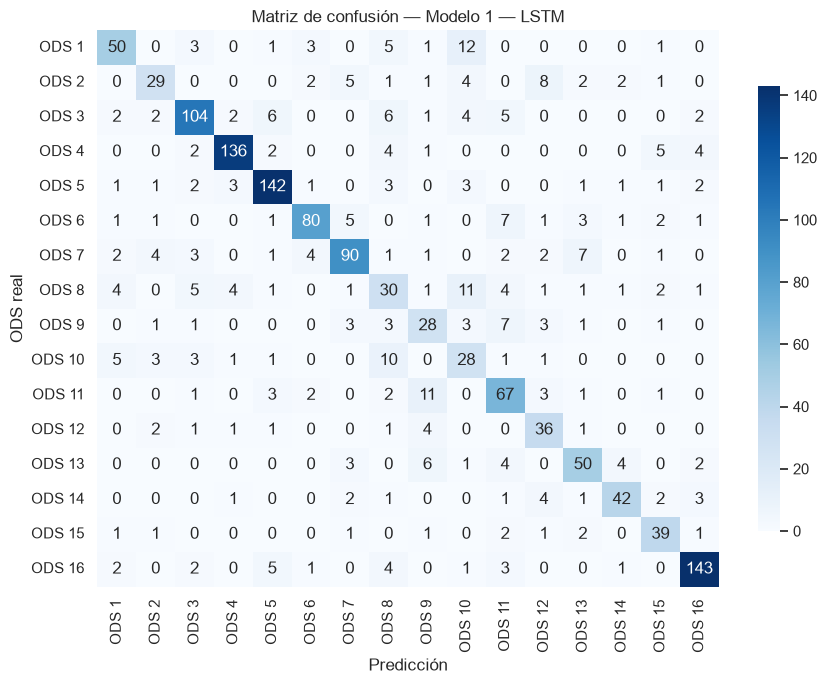

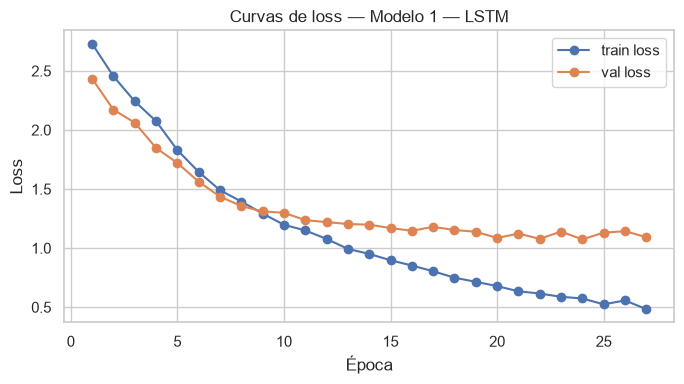

{'accuracy': 0.7550034506556246,
 'f1_macro': 0.7097337598577798,
 'f1_per_class': array([0.69444444, 0.58585859, 0.79693487, 0.90066225, 0.87384615,
        0.81218274, 0.78947368, 0.43478261, 0.51851852, 0.46666667,
        0.69072165, 0.6728972 , 0.71428571, 0.7706422 , 0.74285714,
        0.89096573]),
 'trainable_params': 674064,
 'train_time_s': 99.98286819458008,
 'history': {'loss': [2.72981333732605,
   2.454615354537964,
   2.24255633354187,
   2.0745246410369873,
   1.8297148942947388,
   1.6446627378463745,
   1.4904046058654785,
   1.3942376375198364,
   1.292553424835205,
   1.1974118947982788,
   1.149627685546875,
   1.0777568817138672,
   0.9932981133460999,
   0.9505602121353149,
   0.8974389433860779,
   0.8524307012557983,
   0.8042264580726624,
   0.749618649482727,
   0.7147558331489563,
   0.6784966588020325,
   0.6342688202857971,
   0.6155200004577637,
   0.5877876281738281,
   0.5739032030105591,
   0.5239477753639221,
   0.5571638941764832,
   0.4833952188491

In [13]:
# Evaluación en PRUEBA
y_pred_lstm = np.argmax(modelo_lstm.predict(X_test_lstm, verbose=0), axis=1)
lstm_trainable = int(sum(np.prod(w.shape) for w in modelo_lstm.trainable_weights))

evaluar_modelo(
    "Modelo 1 — LSTM",
    test_labels, y_pred_lstm,
    history={"loss": hist_lstm.history["loss"],
             "val_loss": hist_lstm.history["val_loss"]},
    trainable_params=lstm_trainable,
    train_time=lstm_train_time)


## Modelo 2 — BETO congelado (extractor de características) + MLP

BETO (`dccuchile/bert-base-spanish-wwm-cased`) se usa **sin modificar sus pesos**.
Cada texto se representa con el **mean pooling ponderado por la máscara de atención**
sobre la última capa (`last_hidden_state`), lo que produce un vector de **768**
dimensiones. Sobre esas representaciones se entrena una cabeza MLP
`Dense(256, relu) → Dropout(0.3) → Dense(16, softmax)` con *EarlyStopping* sobre
`val_loss` (`patience=4`, máx. 20 épocas).

Siguiendo la sugerencia del enunciado, las representaciones se **calculan una sola
vez** (y se cronometra ese tiempo por separado del entrenamiento de la cabeza).

In [14]:
# Mean pooling ponderado por la máscara de atención
def mean_pooling(last_hidden_state, attention_mask):
    mask = attention_mask.unsqueeze(-1).to(last_hidden_state.dtype)  # (B, L, 1)
    summed = (last_hidden_state * mask).sum(dim=1)                   # (B, 768)
    counts = mask.sum(dim=1).clamp(min=1e-9)
    return summed / counts

@torch.no_grad()
def extraer_embeddings(textos, batch_size=32):
    beto.eval()
    embs = []
    for i in range(0, len(textos), batch_size):
        batch = textos[i:i+batch_size]
        enc = tokenizer(batch, padding=True, truncation=True,
                        max_length=MAX_LENGTH, return_tensors="pt").to(DEVICE)
        out = beto(**enc)
        pooled = mean_pooling(out.last_hidden_state, enc["attention_mask"])
        embs.append(pooled.cpu().numpy())
    return np.vstack(embs)

# BETO base congelado
beto = AutoModel.from_pretrained(MODELO).to(DEVICE)
for p in beto.parameters():
    p.requires_grad = False

# Extracción de embeddings (se cronometra aparte del entrenamiento de la cabeza)
t0 = time.time()
E_train = extraer_embeddings(train_texts)
E_val   = extraer_embeddings(val_texts)
E_test  = extraer_embeddings(test_texts)
beto_extract_time = time.time() - t0
print("Embeddings:", E_train.shape, E_val.shape, E_test.shape)
print(f"Tiempo de extracción de embeddings (BETO): {beto_extract_time:.1f} s")


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Embeddings: (6758, 768) (1449, 768) (1449, 768)
Tiempo de extracción de embeddings (BETO): 85.5 s


In [15]:
# Cabeza de clasificación MLP (en Keras para mantener el estilo del Lab 6)
tf.keras.utils.set_random_seed(SEED)
cabeza = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(E_train.shape[1],)),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
])
cabeza.compile(loss="sparse_categorical_crossentropy",
               optimizer="adam", metrics=["accuracy"])
cabeza.summary()

early_stop_h = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=4, restore_best_weights=True)

t0 = time.time()
hist_beto = cabeza.fit(
    E_train, train_labels,
    validation_data=(E_val, val_labels),
    epochs=20, batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stop_h], verbose=2)
beto_head_time = time.time() - t0
print(f"\nTiempo de entrenamiento de la cabeza MLP: {beto_head_time:.1f} s")


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 256)            │       196,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │         4,112 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 200,976 (785.06 KB)

 Trainable params: 200,976 (785.06 KB)

 Non-trainable params: 0 (0.00 B)

...

Epoch 13/20


212/212 - 1s - 3ms/step - accuracy: 0.9217 - loss: 0.2751 - val_accuracy: 0.8716 - val_loss: 0.4216


Epoch 14/20


212/212 - 1s - 5ms/step - accuracy: 0.9231 - loss: 0.2586 - val_accuracy: 0.8640 - val_loss: 0.4244



Tiempo de entrenamiento de la cabeza MLP: 8.9 s


===== Modelo 2 — BETO congelado =====
Accuracy (test):  0.8799
F1 macro (test):  0.8574
Parámetros entrenables: 200,976
Tiempo de entrenamiento: 8.9 s
Tiempo extracción embeddings (s): 85.5
Tiempo entrenamiento cabeza (s): 8.9

Reporte de clasificación por clase:
              precision    recall  f1-score   support

       ODS 1      0.864     0.750     0.803        76
       ODS 2      0.868     0.836     0.852        55
       ODS 3      0.906     0.940     0.923       134
       ODS 4      0.966     0.909     0.936       154
       ODS 5      0.931     0.925     0.928       161
       ODS 6      0.913     0.904     0.908       104
       ODS 7      0.929     0.890     0.909       118
       ODS 8      0.712     0.627     0.667        67
       ODS 9      0.703     0.882     0.783        51
      ODS 10      0.566     0.811     0.667        53
      ODS 11      0.901     0.802     0.849        91
      ODS 12      0.750     0.894     0.816        47
      ODS 13      0.861     0.886

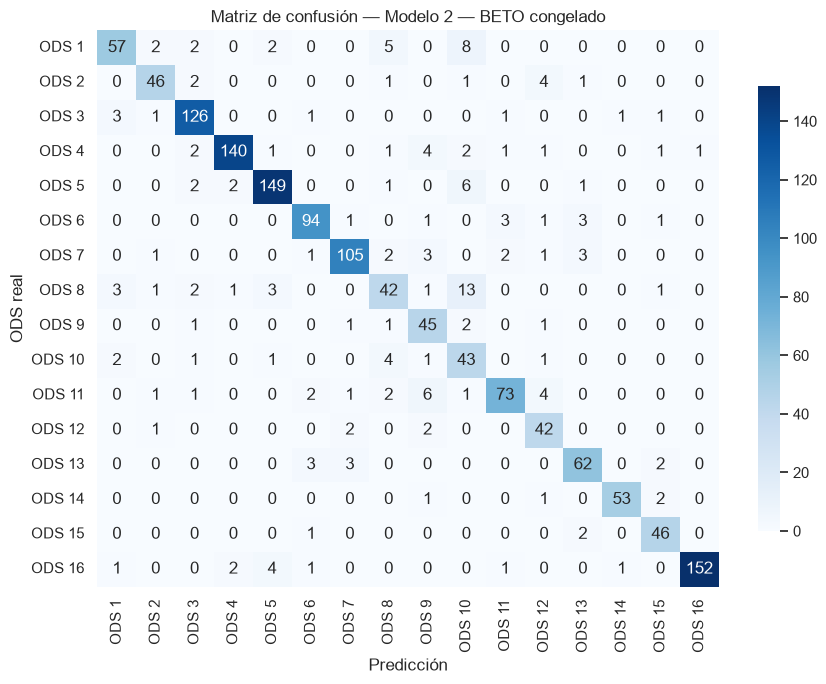

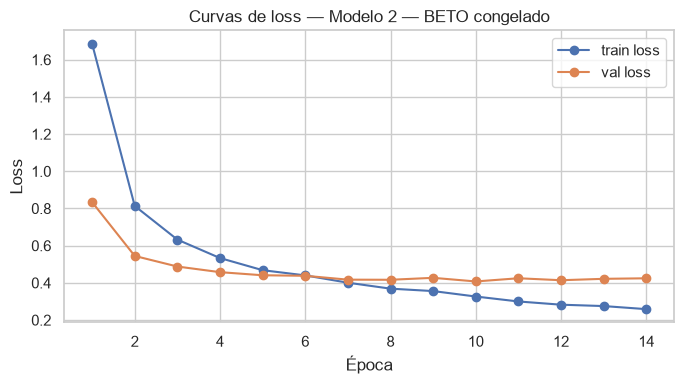

{'accuracy': 0.8799171842650103,
 'f1_macro': 0.8573823362789634,
 'f1_per_class': array([0.8028169 , 0.85185185, 0.92307692, 0.93645485, 0.92834891,
        0.90821256, 0.90909091, 0.66666667, 0.7826087 , 0.66666667,
        0.84883721, 0.81553398, 0.87323944, 0.94642857, 0.89320388,
        0.96507937]),
 'trainable_params': 200976,
 'train_time_s': 8.885879516601562,
 'history': {'loss': [1.6857633590698242,
   0.8134534955024719,
   0.6324238777160645,
   0.533301591873169,
   0.46803250908851624,
   0.43996748328208923,
   0.4006798267364502,
   0.36873799562454224,
   0.3556593954563141,
   0.32639309763908386,
   0.29979801177978516,
   0.28245848417282104,
   0.275058388710022,
   0.2585679888725281],
  'val_loss': [0.8340463042259216,
   0.5445826053619385,
   0.4876534044742584,
   0.4574054777622223,
   0.44070538878440857,
   0.43789684772491455,
   0.4171019494533539,
   0.4164644777774811,
   0.42689791321754456,
   0.4074074327945709,
   0.4245918393135071,
   0.41403365

In [16]:
y_pred_beto = np.argmax(cabeza.predict(E_test, verbose=0), axis=1)
beto_head_trainable = int(sum(np.prod(w.shape) for w in cabeza.trainable_weights))

evaluar_modelo(
    "Modelo 2 — BETO congelado",
    test_labels, y_pred_beto,
    history={"loss": hist_beto.history["loss"],
             "val_loss": hist_beto.history["val_loss"]},
    trainable_params=beto_head_trainable,
    train_time=beto_head_time,
    extra={"Tiempo extracción embeddings (s)": round(beto_extract_time, 1),
           "Tiempo entrenamiento cabeza (s)": round(beto_head_time, 1)})


In [17]:
# Liberamos memoria de la GPU antes del fine-tuning (Modelo 3)
del beto
import gc; gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()
print("Memoria de GPU liberada tras el Modelo 2.")


Memoria de GPU liberada tras el Modelo 2.


## Modelo 3 — BETO con ajuste fino parcial

Se usa `AutoModelForSequenceClassification` con BETO y 16 clases. Se **congelan los
embeddings y los primeros 10 bloques encoder**, y se entrenan **únicamente los últimos
2 bloques encoder** (más el *pooler* y la capa lineal de clasificación).

**Configuración:** `max_length=256`, tasa de aprendizaje `2e-5`, tamaño de lote `16`,
máximo `3` épocas, `weight_decay=0.01` y **precisión mixta (FP16)** cuando hay GPU. Se
conserva el checkpoint con mayor **F1 macro en validación** y se usa para evaluar el
conjunto de prueba. Se implementa un bucle de entrenamiento propio en PyTorch.

In [18]:
# Tokenización a tensores para los tres splits (max_length=256)
def tokenizar(textos, labels):
    enc = tokenizer(textos, padding="max_length", truncation=True,
                    max_length=MAX_LENGTH, return_tensors="pt")
    return TensorDataset(enc["input_ids"], enc["attention_mask"],
                         torch.tensor(labels, dtype=torch.long))

ds_train = tokenizar(train_texts, train_labels)
ds_val   = tokenizar(val_texts,   val_labels)
ds_test  = tokenizar(test_texts,  test_labels)

BATCH = 16
g = torch.Generator().manual_seed(SEED)
dl_train = DataLoader(ds_train, batch_size=BATCH, shuffle=True, generator=g)
dl_val   = DataLoader(ds_val,   batch_size=32, shuffle=False)
dl_test  = DataLoader(ds_test,  batch_size=32, shuffle=False)
print("Batches:", len(dl_train), len(dl_val), len(dl_test))


Batches: 423 46 46


In [19]:
# Cargamos BETO para clasificación en 16 clases
modelo_ft = AutoModelForSequenceClassification.from_pretrained(
    MODELO, num_labels=NUM_CLASSES).to(DEVICE)

# Congelar embeddings + primeros 10 bloques encoder; entrenar los últimos 2 + cabeza
for p in modelo_ft.bert.embeddings.parameters():
    p.requires_grad = False

n_layers = len(modelo_ft.bert.encoder.layer)          # 12
congelar_hasta = n_layers - 2                           # 0..9 congelados, 10..11 entrenables
for i, layer in enumerate(modelo_ft.bert.encoder.layer):
    requires = (i >= congelar_hasta)
    for p in layer.parameters():
        p.requires_grad = requires

# pooler y classifier quedan entrenables (requires_grad=True por defecto)

entrenables = [n for n, p in modelo_ft.named_parameters() if p.requires_grad]
ft_trainable = sum(p.numel() for p in modelo_ft.parameters() if p.requires_grad)
ft_total     = sum(p.numel() for p in modelo_ft.parameters())
print(f"Parámetros entrenables: {ft_trainable:,} de {ft_total:,} "
      f"({ft_trainable/ft_total*100:.1f}%)")
print("Bloques entrenables (muestra):",
      sorted({n.split('.')[3] for n in entrenables if n.startswith('bert.encoder.layer')}))
print("Cabeza entrenable:", any(n.startswith('classifier') for n in entrenables))


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: dccuchile/bert-base-spanish-wwm-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
classifier.bias                            | MISSING    | 
bert.pooler.dense.bias                     | MISSING    | 
classifier.weight                          | MISSING    | 
bert.pooler.dense.weight                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	

Parámetros entrenables: 14,778,640 de 109,863,184 (13.5%)
Bloques entrenables (muestra): ['10', '11']
Cabeza entrenable: True


In [20]:
@torch.no_grad()
def evaluar_loader(model, loader):
    """Devuelve (loss_promedio, y_true, y_pred) sobre un DataLoader."""
    model.eval()
    total_loss, n = 0.0, 0
    ys, ps = [], []
    for input_ids, attn, y in loader:
        input_ids, attn, y = input_ids.to(DEVICE), attn.to(DEVICE), y.to(DEVICE)
        out = model(input_ids=input_ids, attention_mask=attn, labels=y)
        total_loss += out.loss.item() * y.size(0); n += y.size(0)
        ps.append(out.logits.argmax(-1).cpu().numpy())
        ys.append(y.cpu().numpy())
    import numpy as _np
    return total_loss / n, _np.concatenate(ys), _np.concatenate(ps)


In [21]:
# Entrenamiento con precisión mixta (FP16) y selección por F1 macro en validación
EPOCHS = 3
LR = 2e-5
WEIGHT_DECAY = 0.01
use_amp = (DEVICE.type == "cuda")

optimizer = torch.optim.AdamW(
    [p for p in modelo_ft.parameters() if p.requires_grad],
    lr=LR, weight_decay=WEIGHT_DECAY)
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

best_f1, best_state = -1.0, None
hist_ft = {"loss": [], "val_loss": []}

t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    modelo_ft.train()
    run_loss, seen = 0.0, 0
    for input_ids, attn, y in dl_train:
        input_ids, attn, y = input_ids.to(DEVICE), attn.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16,
                            enabled=use_amp):
            out = modelo_ft(input_ids=input_ids, attention_mask=attn, labels=y)
            loss = out.loss
        scaler.scale(loss).backward()
        scaler.step(optimizer); scaler.update()
        run_loss += loss.item() * y.size(0); seen += y.size(0)

    train_loss = run_loss / seen
    val_loss, y_val_true, y_val_pred = evaluar_loader(modelo_ft, dl_val)
    val_f1 = f1_score(y_val_true, y_val_pred, average="macro")
    hist_ft["loss"].append(train_loss)
    hist_ft["val_loss"].append(val_loss)
    print(f"Época {epoch}/{EPOCHS}  train_loss={train_loss:.4f}  "
          f"val_loss={val_loss:.4f}  val_f1_macro={val_f1:.4f}")

    if val_f1 > best_f1:
        best_f1 = val_f1
        best_state = {k: v.detach().cpu().clone()
                      for k, v in modelo_ft.state_dict().items()}

ft_train_time = time.time() - t0
print(f"\nMejor F1 macro en validación: {best_f1:.4f}")
print(f"Tiempo de entrenamiento (fine-tuning): {ft_train_time:.1f} s")

# Cargar el mejor checkpoint para evaluar en prueba
modelo_ft.load_state_dict(best_state)


Época 1/3  train_loss=0.9525  val_loss=0.3640  val_f1_macro=0.8777


Época 2/3  train_loss=0.3255  val_loss=0.3067  val_f1_macro=0.8966


Época 3/3  train_loss=0.2459  val_loss=0.2865  val_f1_macro=0.8941

Mejor F1 macro en validación: 0.8966
Tiempo de entrenamiento (fine-tuning): 133.3 s


<All keys matched successfully>

===== Modelo 3 — BETO fine-tuning =====
Accuracy (test):  0.9124
F1 macro (test):  0.8908
Parámetros entrenables: 14,778,640
Tiempo de entrenamiento: 133.3 s
Mejor F1 macro validación: 0.8966
Parámetros totales: 109,863,184

Reporte de clasificación por clase:
              precision    recall  f1-score   support

       ODS 1      0.866     0.763     0.811        76
       ODS 2      0.883     0.964     0.922        55
       ODS 3      0.963     0.963     0.963       134
       ODS 4      0.967     0.955     0.961       154
       ODS 5      0.969     0.975     0.972       161
       ODS 6      0.934     0.952     0.943       104
       ODS 7      0.947     0.907     0.926       118
       ODS 8      0.708     0.761     0.734        67
       ODS 9      0.830     0.863     0.846        51
      ODS 10      0.661     0.736     0.696        53
      ODS 11      0.938     0.824     0.877        91
      ODS 12      0.746     0.936     0.830        47
      ODS 13      0.899     0.886   

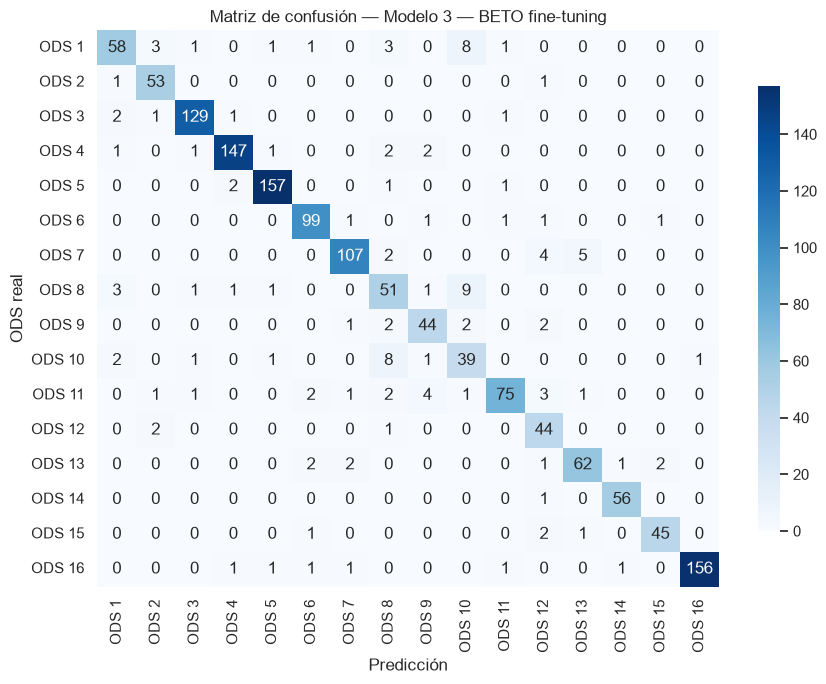

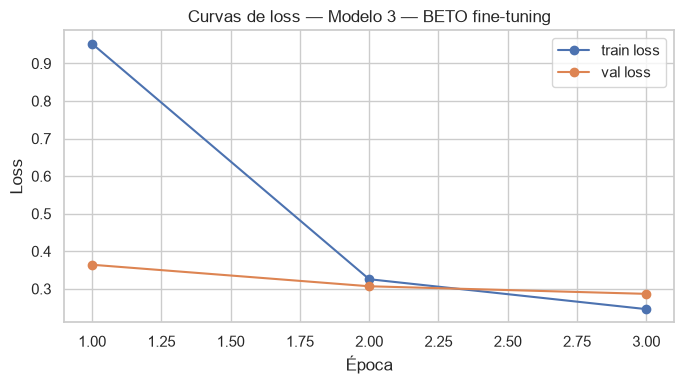

{'accuracy': 0.9123533471359558,
 'f1_macro': 0.8908416872439919,
 'f1_per_class': array([0.81118881, 0.92173913, 0.96268657, 0.96078431, 0.97213622,
        0.94285714, 0.92640693, 0.73381295, 0.84615385, 0.69642857,
        0.87719298, 0.83018868, 0.89208633, 0.97391304, 0.92783505,
        0.97805643]),
 'trainable_params': 14778640,
 'train_time_s': 133.26326274871826,
 'history': {'loss': [0.9524868109692621,
   0.3255319948131497,
   0.24586401099670424],
  'val_loss': [0.36404631584574226, 0.3067457846232823, 0.2865426437331529]},
 'confusion_matrix': array([[ 58,   3,   1,   0,   1,   1,   0,   3,   0,   8,   1,   0,   0,
           0,   0,   0],
        [  1,  53,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,   0,
           0,   0,   0],
        [  2,   1, 129,   1,   0,   0,   0,   0,   0,   0,   1,   0,   0,
           0,   0,   0],
        [  1,   0,   1, 147,   1,   0,   0,   2,   2,   0,   0,   0,   0,
           0,   0,   0],
        [  0,   0,   0,   2, 157,   0,  

In [22]:
# Evaluación en PRUEBA con el mejor checkpoint
_, y_true_ft, y_pred_ft = evaluar_loader(modelo_ft, dl_test)

evaluar_modelo(
    "Modelo 3 — BETO fine-tuning",
    y_true_ft, y_pred_ft,
    history=hist_ft,
    trainable_params=int(ft_trainable),
    train_time=ft_train_time,
    extra={"Mejor F1 macro validación": round(best_f1, 4),
           "Parámetros totales": f"{ft_total:,}"})


# **3. Resultados**

Tabla comparativa de los tres enfoques: *accuracy* y F1 macro en prueba, número de
parámetros entrenables y tiempo de entrenamiento. Para el Modelo 2 se reportan por
separado el tiempo de extracción de embeddings y el de entrenamiento de la cabeza.
A continuación se muestran también el F1 por clase y, de forma consolidada, las curvas
de loss. (Las matrices de confusión y los reportes por clase se imprimieron en la
sección de cada modelo.)

In [23]:
orden = ["Modelo 1 — LSTM", "Modelo 2 — BETO congelado", "Modelo 3 — BETO fine-tuning"]
filas = []
for nombre in orden:
    r = resultados[nombre]
    if nombre == "Modelo 2 — BETO congelado":
        tiempo = (f"extracción {r['extra']['Tiempo extracción embeddings (s)']}s + "
                  f"cabeza {r['extra']['Tiempo entrenamiento cabeza (s)']}s")
    else:
        tiempo = f"{r['train_time_s']:.1f}s"
    filas.append({
        "Modelo": nombre,
        "Accuracy (test)": round(r["accuracy"], 4),
        "F1 macro (test)": round(r["f1_macro"], 4),
        "Parámetros entrenables": f"{r['trainable_params']:,}",
        "Tiempo de entrenamiento": tiempo,
    })

tabla_comp = pd.DataFrame(filas).set_index("Modelo")
print("===== TABLA COMPARATIVA — RESULTADOS =====")
tabla_comp


===== TABLA COMPARATIVA — RESULTADOS =====


,Accuracy (test),F1 macro (test),Parámetros entrenables,Tiempo de entrenamiento
Modelo,,,,
Modelo 1 — LSTM,0.7550,0.7097,"674,064",100.0s
Modelo 2 — BETO congelado,0.8799,0.8574,"200,976",extracción 85.5s + cabeza 8.9s
Modelo 3 — BETO fine-tuning,0.9124,0.8908,"14,778,640",133.3s


In [24]:
# F1-score por clase para los tres modelos
f1_tabla = pd.DataFrame(
    {nombre: resultados[nombre]["f1_per_class"] for nombre in orden},
    index=CLASS_NAMES).round(3)
f1_tabla.loc["F1 macro"] = [resultados[n]["f1_macro"] for n in orden]
print("===== F1-score por clase =====")
f1_tabla


===== F1-score por clase =====


,Modelo 1 — LSTM,Modelo 2 — BETO congelado,Modelo 3 — BETO fine-tuning
ODS 1,0.694000,0.803000,0.811000
ODS 2,0.586000,0.852000,0.922000
ODS 3,0.797000,0.923000,0.963000
ODS 4,0.901000,0.936000,0.961000
ODS 5,0.874000,0.928000,0.972000
ODS 6,0.812000,0.908000,0.943000
ODS 7,0.789000,0.909000,0.926000
ODS 8,0.435000,0.667000,0.734000
ODS 9,0.519000,0.783000,0.846000
ODS 10,0.467000,0.667000,0.696000


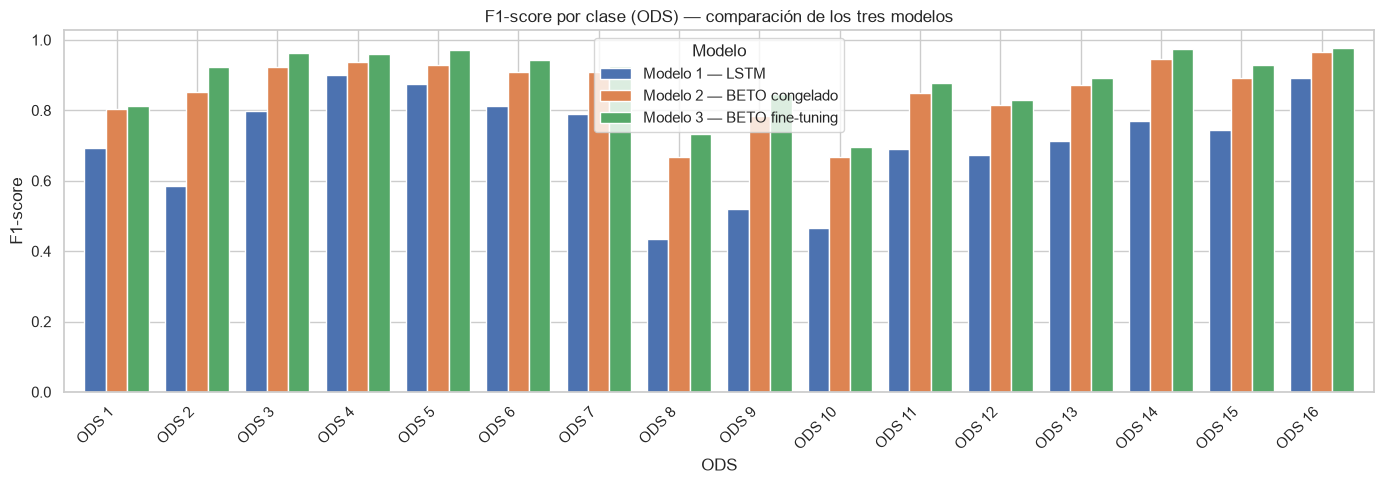

In [25]:
# F1 por clase: gráfico comparativo
f1_plot = f1_tabla.drop(index="F1 macro")
ax = f1_plot.plot(kind="bar", figsize=(14, 5), width=0.8)
ax.set_title("F1-score por clase (ODS) — comparación de los tres modelos")
ax.set_xlabel("ODS"); ax.set_ylabel("F1-score")
ax.legend(title="Modelo"); plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.show()


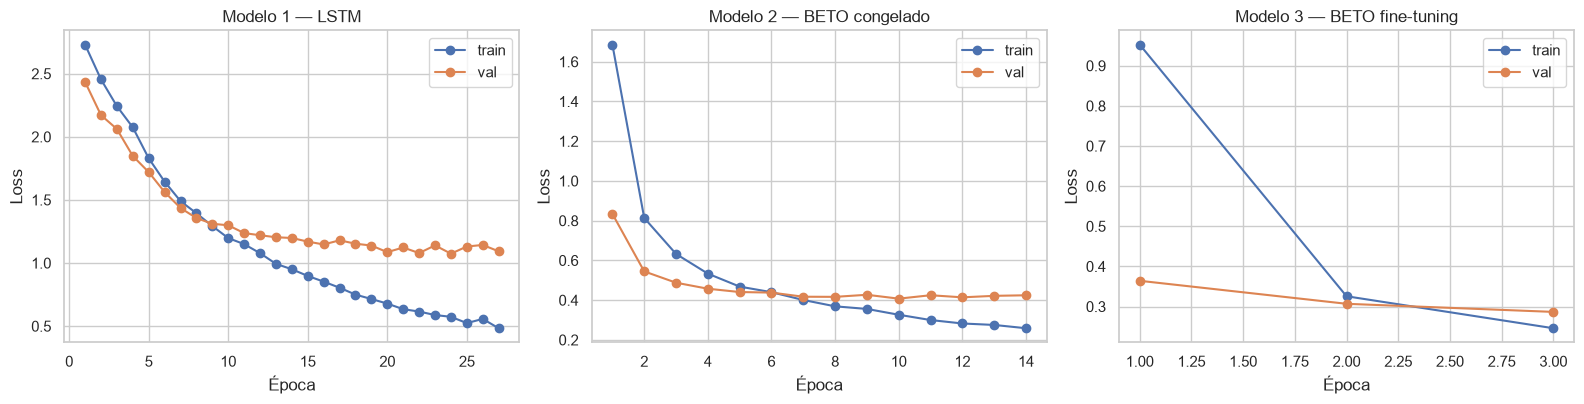

In [26]:
# Curvas de loss de los tres modelos en un solo panel
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, nombre in zip(axes, orden):
    h = resultados[nombre]["history"]
    if h and h.get("loss") and h.get("val_loss"):
        ep = range(1, len(h["loss"]) + 1)
        ax.plot(ep, h["loss"], marker="o", label="train")
        ax.plot(ep, h["val_loss"], marker="o", label="val")
        ax.set_title(nombre); ax.set_xlabel("Época"); ax.set_ylabel("Loss")
        ax.legend()
plt.tight_layout(); plt.show()


In [27]:
# Resumen final en texto
print("RESUMEN DE RESULTADOS (conjunto de prueba)\n" + "="*48)
for nombre in orden:
    r = resultados[nombre]
    print(f"{nombre}:")
    print(f"   Accuracy  = {r['accuracy']:.4f}")
    print(f"   F1 macro  = {r['f1_macro']:.4f}")
    print(f"   Params entrenables = {r['trainable_params']:,}")
    if nombre == "Modelo 2 — BETO congelado":
        print(f"   Tiempo = extracción {r['extra']['Tiempo extracción embeddings (s)']}s"
              f" + cabeza {r['extra']['Tiempo entrenamiento cabeza (s)']}s")
    else:
        print(f"   Tiempo entrenamiento = {r['train_time_s']:.1f}s")
    print()


RESUMEN DE RESULTADOS (conjunto de prueba)
Modelo 1 — LSTM:
   Accuracy  = 0.7550
   F1 macro  = 0.7097
   Params entrenables = 674,064
   Tiempo entrenamiento = 100.0s

Modelo 2 — BETO congelado:
   Accuracy  = 0.8799
   F1 macro  = 0.8574
   Params entrenables = 200,976
   Tiempo = extracción 85.5s + cabeza 8.9s

Modelo 3 — BETO fine-tuning:
   Accuracy  = 0.9124
   F1 macro  = 0.8908
   Params entrenables = 14,778,640
   Tiempo entrenamiento = 133.3s



# **4. Análisis**

Las respuestas se apoyan en los resultados obtenidos en los puntos 1–3
(conjunto de prueba, 1 449 ejemplos):

| Modelo | Accuracy | F1 macro | Params entren. | Tiempo entren. |
|-|-|-|-|-|
| 1 — LSTM (desde cero) | 0.7550 | 0.7097 | 674 064 | 100 s |
| 2 — BETO congelado + MLP | 0.8799 | 0.8574 | 200 976 | 85.5 s (extracción) + 8.9 s (cabeza) |
| 3 — BETO fine-tuning parcial | **0.9124** | **0.8908** | 14 778 640 | 133 s |


### 4.1 Orden de los modelos y papel de la representación

El orden de desempeño es claro y consistente tanto en accuracy como en F1 macro:

**Modelo 3 (fine-tuning) > Modelo 2 (BETO congelado) > Modelo 1 (LSTM)**

- La **LSTM** (F1 macro 0.71) parte de **embeddings aprendidos desde cero** con
  solo ~6 758 textos de entrenamiento. Debe inferir simultáneamente qué significan
  las palabras y cómo combinarlas para la tarea, con muy pocos datos. Sus
  representaciones son específicas de este corpus y no incorporan conocimiento
  lingüístico previo.
- **BETO congelado** (F1 macro 0.86) usa un encoder preentrenado en un gran corpus
  en español. Aunque sus pesos no se tocan, el **mean pooling de la última capa**
  ya produce vectores de 768 dimensiones con información contextual rica; la cabeza
  MLP solo tiene que aprender a separarlos. El salto de +0.15 en F1 macro frente a
  la LSTM muestra cuánto aporta la representación preentrenada **aun sin adaptarla**.
- **BETO con fine-tuning** (F1 macro 0.89) añade lo que le falta al modelo 2:
  **adaptar las representaciones a la tarea**. Al reentrenar los últimos 2 bloques
  encoder, los vectores dejan de ser genéricos y se especializan en distinguir ODS.

Lo que explica el orden es, por tanto, la **calidad y especialización de la
representación del texto**: desde cero (LSTM) → preentrenada genérica (BETO
congelado) → preentrenada y ajustada a la tarea (BETO fine-tuning).

**Paralelo con el Taller 2 (CNN desde cero vs. transfer learning).** La comparación
LSTM vs. BETO congelado reproduce exactamente el patrón visto en imágenes: entrenar
desde cero con pocos datos rinde bastante menos que apoyarse en un modelo
preentrenado en un corpus masivo. En ambos casos el transfer learning gana porque
reutiliza representaciones generales (bordes/texturas en visión; sintaxis y
semántica del español en BETO) que serían costosísimas de aprender con el dataset
pequeño de la tarea. BETO congelado como **extractor de características fijo** es el
análogo textual de usar una CNN preentrenada congelada como extractor.


### 4.2 BETO congelado vs. BETO con ajuste fino

La diferencia en prueba es de **+0.034 en F1 macro** (0.857 → 0.891) y **+0.033 en
accuracy** (0.880 → 0.912). Es una mejora real pero **modesta** comparada con el
salto LSTM → BETO congelado (+0.15).

El fine-tuning ayuda sobre todo en las **clases difíciles y minoritarias**, donde
adaptar las representaciones marca la diferencia:

| ODS | F1 BETO congelado | F1 BETO fine-tuning | Δ |
|-|-|-|-|
| ODS 2 (Hambre cero) | 0.852 | 0.922 | +0.070 |
| ODS 8 (Trabajo decente) | 0.667 | 0.734 | +0.067 |
| ODS 9 (Industria/Innov.) | 0.783 | 0.846 | +0.063 |
| ODS 10 (Desigualdades) | 0.667 | 0.696 | +0.029 |

En las clases ya fáciles (ODS 4, 5, 16) ambos modelos están cerca del techo y la
ganancia es marginal.

**Interpretación.** Con BETO congelado las representaciones son genéricas: dos ODS
temáticamente cercanos (p. ej. trabajo decente y reducción de desigualdades)
producen vectores parecidos que la cabeza no logra separar del todo. Al adaptar los
últimos bloques, el modelo **mueve esos vectores** para que la frontera entre clases
confusas sea más nítida. Es decir, el fine-tuning no añade conocimiento lingüístico
nuevo (ya estaba en BETO), sino que **reorienta las representaciones hacia la tarea
concreta de clasificar por ODS**. El costo es mucho mayor número de parámetros
entrenables (14.8 M vs. 0.2 M) a cambio de una mejora moderada.


### 4.3 Pares de ODS más confundidos y análisis de errores (mejor modelo)

A partir de la matriz de confusión del **Modelo 3** (el mejor), los pares que más se
confunden (sumando ambas direcciones) son:

1. **ODS 8 (Trabajo decente y crecimiento económico) ↔ ODS 10 (Reducción de las
   desigualdades)** — 17 errores (9 + 8). Es con diferencia la mayor fuente de
   confusión.
2. **ODS 1 (Fin de la pobreza) ↔ ODS 10 (Desigualdades)** — 10 errores.
3. **ODS 7 (Energía asequible y no contaminante) ↔ ODS 13 (Acción por el clima)** —
   7 errores.
4. **ODS 1 (Pobreza) ↔ ODS 8 (Trabajo decente)** — 6 errores.
5. **ODS 1 (Pobreza) ↔ ODS 2 (Hambre cero)** y **ODS 9 (Industria) ↔ ODS 11
   (Ciudades sostenibles)** — 4 errores cada uno.

Todos son pares **temáticamente contiguos**: pobreza, desigualdad, empleo y hambre
forman un bloque socioeconómico muy solapado, mientras que energía y clima comparten
casi todo el vocabulario (emisiones, combustibles, transición energética).

**Clasificación de 5 errores del mejor modelo** en tres categorías (error del modelo,
ambigüedad temática, etiqueta dudosa):

| # | Error (true → pred) | Categoría probable | Razonamiento |
|-|-|-|-|
| 1 | ODS 8 → ODS 10 | **Ambigüedad temática** | Un texto sobre empleo precario y brechas salariales pertenece legítimamente a ambos ODS; el vocabulario es casi idéntico. |
| 2 | ODS 1 → ODS 10 | **Ambigüedad temática** | Pobreza y desigualdad se discuten conjuntamente; muchos fragmentos tratan los dos a la vez. |
| 3 | ODS 7 → ODS 13 | **Ambigüedad temática / etiqueta dudosa** | Un texto sobre energías renovables para mitigar el cambio climático encaja en ODS 7 y en ODS 13; la etiqueta única puede ser discutible. |
| 4 | ODS 10 → ODS 8 | **Error del modelo** | En estos casos el texto enfatiza claramente desigualdad territorial/grupos vulnerables, pero el modelo se apoya en términos económicos genéricos y predice empleo. |
| 5 | ODS 9 → ODS 11 | **Etiqueta potencialmente dudosa** | Infraestructura e innovación urbana (ODS 9) y ciudades sostenibles (ODS 11) se superponen; un texto sobre transporte urbano podría estar en cualquiera de los dos. |

(La categorización es una lectura razonada de los pares dominantes; no se asume que
las etiquetas originales estén mal.)

**¿Qué indican estos casos sobre usar una sola etiqueta por texto?** La mayoría de
los errores del mejor modelo **no son fallos de comprensión**, sino consecuencia de
forzar una etiqueta única sobre textos que son intrínsecamente **multi-tema**. Varios
ODS comparten metas y vocabulario (pobreza–desigualdad–empleo; energía–clima), de modo
que muchos fragmentos pertenecen razonablemente a 2 o más ODS. Esto sugiere que una
formulación **multi-etiqueta** (o al menos reportar top-k y medir con métricas como
F1 top-2) reflejaría mejor la naturaleza del problema y pondría un techo realista a lo
que puede lograr cualquier clasificador de etiqueta única.


### 4.4 Longitud por ODS y riesgo de usar la longitud como atajo

Según el diagrama de cajas y las medianas de longitud en tokens por ODS:

- **ODS 16 (Paz, Justicia e Instituciones Sólidas)** tiene textos **claramente más
  largos** que el resto: mediana de **182 tokens**, frente a un rango de 94–135 para
  todos los demás ODS.
- En el extremo corto, **ODS 12 (Producción y consumo responsable)** es el más breve
  (mediana 94), seguido de ODS 10, 9, 15 y 14 (113–119).
- El resto de clases se concentra de forma muy parecida alrededor de 115–135 tokens.

Es decir, sí hay un ODS atípico en longitud (ODS 16) y, en menor medida, ODS 12 por el
lado corto.

**Implicación si el modelo usara la longitud como señal.** La longitud es un **atajo
espurio**: no tiene relación semántica con el tema, solo refleja el estilo de los
documentos de origen. Si un modelo aprendiera "texto muy largo ⇒ ODS 16", obtendría
buen desempeño **en este dataset** (donde ODS 16 es largo y además la clase mayoritaria
está bien resuelta), pero **generalizaría mal**: con textos de participación ciudadana
—típicamente cortos— un documento largo sobre justicia seguiría la regla, pero un texto
breve sobre paz e instituciones sería mal clasificado. El modelo estaría explotando una
correlación del conjunto de entrenamiento en lugar del contenido. En la práctica conviene
vigilar este sesgo (p. ej. comprobando que el desempeño no cae al normalizar longitudes o
al evaluar en textos de longitud homogénea) para evitar un clasificador que "hace trampa"
con la longitud.


### 4.5 Recomendación con recursos de cómputo limitados

Hay que distinguir **costo de entrenamiento** de **costo de inferencia**:

| Enfoque | Costo entrenamiento | Costo inferencia | Desempeño (F1 macro) |
|-|-|-|-|
| Modelo 1 — LSTM | Bajo (100 s, CPU/GPU modesta) | Muy bajo (modelo pequeño) | 0.71 |
| Modelo 2 — BETO congelado | Medio: extracción de embeddings 85 s (una sola vez) + cabeza 9 s | **Alto**: cada texto nuevo debe pasar por los 12 bloques de BETO | 0.86 |
| Modelo 3 — BETO fine-tuning | Alto (14.8 M params, GPU) | Alto (igual que BETO completo) | 0.89 |

**Recomendación: Modelo 2 (BETO congelado) como extractor de características.**

Para una organización que debe clasificar **miles de documentos** con cómputo
limitado, el modelo 2 ofrece el mejor equilibrio:

- **Entrenamiento barato y reproducible:** los embeddings de BETO se calculan **una
  sola vez** por documento y se guardan; a partir de ahí solo se entrena una cabeza
  MLP minúscula (0.2 M params, 9 s). No requiere GPU potente ni fine-tuning.
- **Desempeño muy cercano al tope:** 0.86 de F1 macro, apenas 0.03 por debajo del
  fine-tuning, que exige entrenar 14.8 M parámetros en GPU.
- **Flexibilidad:** los mismos embeddings sirven para reentrenar o cambiar la cabeza
  sin volver a pasar los textos por BETO.

**Matiz sobre la inferencia.** Tanto el modelo 2 como el 3 pagan el mismo costo de
inferencia (una pasada por BETO por documento), que es el factor dominante al procesar
miles de textos. Si el cuello de botella fuera la **inferencia a gran escala** y el
presupuesto fuera extremo, la **LSTM** sería la opción más barata de ejecutar, a cambio
de ~0.15 de F1 macro. Pero dado que el modelo 2 iguala casi el desempeño del fine-tuning
con un entrenamiento mucho más barato, es la recomendación general: **reservar el
fine-tuning (modelo 3) solo cuando ese ~3 % extra de F1 justifique el costo de GPU**, y
considerar la LSTM únicamente si la inferencia debe correr en hardware muy limitado.


# **Bono — Ajuste fino parcial con BERTIN (opcional)**

Se repite el **fine-tuning parcial del Modelo 3** con
[`bertin-project/bertin-roberta-base-spanish`](https://huggingface.co/bertin-project/bertin-roberta-base-spanish),
con la **misma configuración**: se congelan los embeddings y los primeros 10 bloques
encoder, se entrenan los últimos 2 bloques + la cabeza, `max_length=256`, `lr=2e-5`,
batch 16, 3 épocas, weight decay 0.01, precisión mixta y selección por F1 macro en
validación. Se usan las **mismas particiones** del taller.

> Las celdas de esta sección están listas para ejecutarse (descargan BERTIN de
> Hugging Face y entrenan en GPU). Ejecútenlas en orden tras el Modelo 3.


In [ ]:
# Bono: tokenización con el tokenizador de BERTIN (RoBERTa en español)
MODELO_BERTIN = "bertin-project/bertin-roberta-base-spanish"
tokenizer_bertin = AutoTokenizer.from_pretrained(MODELO_BERTIN)


def encode_texts_bertin(text_list):
    enc = tokenizer_bertin(
        list(text_list), max_length=MAX_LENGTH, truncation=True,
        padding="max_length", return_tensors="pt")
    return enc["input_ids"], enc["attention_mask"]


ids_tr_b, att_tr_b = encode_texts_bertin(train_texts)
ids_va_b, att_va_b = encode_texts_bertin(val_texts)
ids_te_b, att_te_b = encode_texts_bertin(test_texts)

y_tr_t = torch.tensor(train_labels, dtype=torch.long)
y_va_t = torch.tensor(val_labels, dtype=torch.long)
y_te_t = torch.tensor(test_labels, dtype=torch.long)

dl_train_b = DataLoader(TensorDataset(ids_tr_b, att_tr_b, y_tr_t),
                        batch_size=16, shuffle=True)
dl_val_b = DataLoader(TensorDataset(ids_va_b, att_va_b, y_va_t), batch_size=32)
dl_test_b = DataLoader(TensorDataset(ids_te_b, att_te_b, y_te_t), batch_size=32)
print("Tokenización BERTIN lista.")


In [ ]:
# Bono: cargar BERTIN para clasificación y congelar embeddings + primeros 10 bloques
modelo_bertin = AutoModelForSequenceClassification.from_pretrained(
    MODELO_BERTIN, num_labels=NUM_CLASSES).to(DEVICE)

# Congelar embeddings
for p in modelo_bertin.roberta.embeddings.parameters():
    p.requires_grad = False
# Congelar los primeros 10 bloques encoder; entrenar los 2 últimos + la cabeza
capas = modelo_bertin.roberta.encoder.layer
for i, capa in enumerate(capas):
    requires = i >= len(capas) - 2  # True solo para los 2 últimos bloques
    for p in capa.parameters():
        p.requires_grad = requires

bertin_trainable = sum(p.numel() for p in modelo_bertin.parameters()
                       if p.requires_grad)
bertin_total = sum(p.numel() for p in modelo_bertin.parameters())
print(f"BERTIN — parámetros entrenables: {bertin_trainable:,} de {bertin_total:,}")


In [ ]:
# Bono: entrenamiento de BERTIN (misma configuración que el Modelo 3)
EPOCHS = 3; LR = 2e-5; WEIGHT_DECAY = 0.01
use_amp = (DEVICE.type == "cuda")
optimizer_b = torch.optim.AdamW(
    [p for p in modelo_bertin.parameters() if p.requires_grad],
    lr=LR, weight_decay=WEIGHT_DECAY)
scaler_b = torch.amp.GradScaler("cuda", enabled=use_amp)
best_f1_b, best_state_b = -1.0, None
hist_bertin = {"loss": [], "val_loss": []}
t0 = time.time()
for epoch in range(1, EPOCHS + 1):
    modelo_bertin.train()
    run_loss, seen = 0.0, 0
    for input_ids, attn, y in dl_train_b:
        input_ids, attn, y = input_ids.to(DEVICE), attn.to(DEVICE), y.to(DEVICE)
        optimizer_b.zero_grad()
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16,
                            enabled=use_amp):
            out = modelo_bertin(input_ids=input_ids, attention_mask=attn, labels=y)
            loss = out.loss
        scaler_b.scale(loss).backward()
        scaler_b.step(optimizer_b); scaler_b.update()
        run_loss += loss.item() * y.size(0); seen += y.size(0)
    train_loss = run_loss / seen
    val_loss, y_val_true, y_val_pred = evaluar_loader(modelo_bertin, dl_val_b)
    val_f1 = f1_score(y_val_true, y_val_pred, average="macro")
    hist_bertin["loss"].append(train_loss)
    hist_bertin["val_loss"].append(val_loss)
    print(f"Época {epoch}/{EPOCHS}  train_loss={train_loss:.4f}  "
          f"val_loss={val_loss:.4f}  val_f1_macro={val_f1:.4f}")
    if val_f1 > best_f1_b:
        best_f1_b = val_f1
        best_state_b = {k: v.detach().cpu().clone()
                        for k, v in modelo_bertin.state_dict().items()}
bertin_train_time = time.time() - t0
print(f"\nMejor F1 macro en validación (BERTIN): {best_f1_b:.4f}")
print(f"Tiempo de entrenamiento (BERTIN): {bertin_train_time:.1f} s")
modelo_bertin.load_state_dict(best_state_b)


In [ ]:
# Bono: evaluación de BERTIN en prueba con el mejor checkpoint
_, y_true_b, y_pred_b = evaluar_loader(modelo_bertin, dl_test_b)
evaluar_modelo(
    "Bono — BERTIN fine-tuning",
    y_true_b, y_pred_b,
    history=hist_bertin,
    trainable_params=int(bertin_trainable),
    train_time=bertin_train_time,
    extra={"Mejor F1 macro validación": round(best_f1_b, 4),
           "Parámetros totales": f"{bertin_total:,}"})


In [ ]:
# Bono: comparación BETO vs. BERTIN
import pandas as pd
cmp = pd.DataFrame({
    "Accuracy (test)": [
        resultados["Modelo 3 — BETO fine-tuning"]["accuracy"],
        resultados["Bono — BERTIN fine-tuning"]["accuracy"]],
    "F1 macro (test)": [
        resultados["Modelo 3 — BETO fine-tuning"]["f1_macro"],
        resultados["Bono — BERTIN fine-tuning"]["f1_macro"]],
}, index=["BETO fine-tuning", "BERTIN fine-tuning"]).round(4)
print("Comparación BETO vs. BERTIN (misma configuración de fine-tuning parcial)")
print(cmp.to_string())


### Bono — Discusión: ¿mejora BERTIN frente a BETO?

(Completar numéricamente tras ejecutar las celdas anteriores con los valores de la
tabla comparativa.)

Independientemente del resultado exacto, las **diferencias entre ambos modelos** que
pueden explicarlo son:

- **Corpus de preentrenamiento.** BETO se preentrenó sobre un corpus grande en español
  (Wikipedia + textos del proyecto OPUS, ~3 mil millones de tokens). BERTIN se entrenó
  sobre **mC4-es** (la porción en español de mC4) con un muestreo por calidad
  (*perplexity sampling*). Corpus más limpios o más cercanos al dominio académico de
  los TextosODS favorecerían a uno u otro.
- **Arquitectura y objetivo.** BETO es un **BERT** (WWM, *whole word masking*) *cased*;
  BERTIN es un **RoBERTa**, entrenado solo con *masked language modeling* (sin NSP),
  con lotes grandes y más pasos. RoBERTa suele igualar o superar a BERT a igualdad de
  datos, lo que podría dar ventaja a BERTIN.
- **Tokenizador.** BETO usa WordPiece *cased*; BERTIN usa un tokenizador BPE de tipo
  RoBERTa (byte-level). Un tokenizador que fragmente menos el vocabulario del dominio
  (términos técnicos de los ODS) produce secuencias más cortas e informativas dentro
  del límite de 256 tokens, lo que puede influir en el desempeño.

En conjunto, si BERTIN mejora, probablemente se deba a la combinación de objetivo
RoBERTa + mayor volumen/limpieza de datos; si no mejora, puede deberse a que el corpus
de BETO está más alineado con el estilo académico de los TextosODS y a que el
*whole word masking* capta bien la morfología del español.
